# How Modern Recommenders Work: From Association Rules to Embeddings and Sequences

*Companion to `01-apriori-grocery-recommender.ipynb`.*

Notebook 01 built a recommender from **association rules**. It had no notion of *who* the user is and no notion of *time*. Real products (Netflix, YouTube, Spotify, Instagram) use more signal. This notebook builds the main ideas behind them from scratch with `numpy`, on a real dataset with real users, and compares them honestly.

**Dataset:** [MovieLens 100K](https://grouplens.org/datasets/movielens/100k/) (GroupLens, University of Minnesota): 100,000 ratings from 943 users on 1,682 movies. Harper & Konstan (2015), *The MovieLens Datasets: History and Context*, ACM TiiS 5(4). It is downloaded on first run (the licence does not allow redistributing it in this repo).

**What you will see**

| # | Section | Idea |
|---|---|---|
| 1 | How a modern system is structured | the retrieval -> ranking -> re-ranking funnel |
| 2 | Explore the data | sparsity, long tail, popularity bias |
| 3 | Evaluate properly | time-based split, full ranking, confidence intervals |
| 4 | Seven recommenders | popularity, association rules, item-kNN, SVD, ALS, BPR, sequence model |
| 5 | Results | accuracy, speed, learning curves |
| 6 | What the model learned | embedding map, nearest neighbours |
| 7 | Beyond accuracy | popularity bias, coverage, cold start |
| 8 | Qualitative example | one user, three models |
| 9 | Where the field is now | two-tower, sequential transformers, generative retrieval |

> Runtime: a few minutes on a laptop CPU, no GPU. Run it from the `notebooks/` folder.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import time, zipfile, urllib.request
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
from sklearn.decomposition import TruncatedSVD
from sklearn.manifold import TSNE

BLUE, ORANGE, AQUA, VIOLET, MAGENTA, GRAY, YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#6250d6", "#e87ba4", "#8a8a85", "#eda100"
sns.set_theme(style="whitegrid", context="notebook", rc={
    "axes.spines.top": False, "axes.spines.right": False, "grid.color": "#e6e6e3",
    "figure.dpi": 110, "axes.titleweight": "bold", "axes.titlesize": 12})
SEQ = sns.light_palette(BLUE, as_cmap=True)
SEED = 0

## 1. How a modern recommender is structured

A catalogue can hold millions of items, so nobody scores every item with a heavy model. Production systems are a **funnel** (e.g. Covington et al., 2016, YouTube):

1. **Retrieval / candidate generation:** a fast model narrows millions of items to hundreds. Typically a *two-tower* model: one network embeds the user, another embeds the item, and relevance is a **dot product**. Dot products allow approximate nearest-neighbour search.
2. **Ranking:** a heavier model scores those few hundred with rich features.
3. **Re-ranking:** business rules and diversity, freshness and fairness adjustments pick the final list.

Everything we build below lives in step 1. The matrix-factorisation models are, in fact, the simplest possible two-tower models (one embedding vector per user, one per item, scored with a dot product).

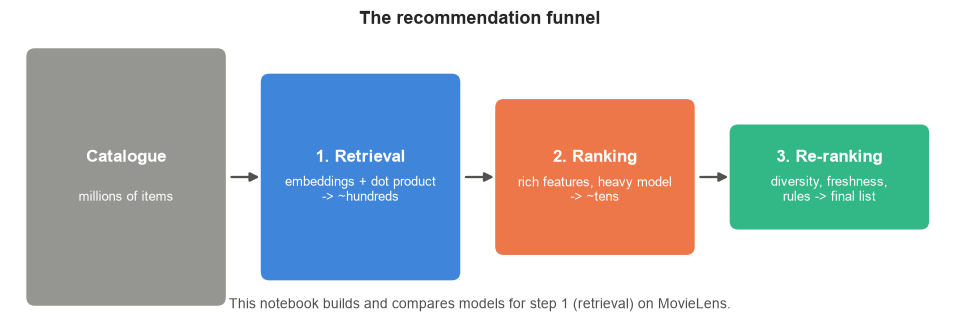

In [2]:
fig, ax = plt.subplots(figsize=(11, 3.4)); ax.axis("off"); ax.set_xlim(0, 11); ax.set_ylim(0, 3.4)
stages = [("Catalogue", "millions of items", 3.0, GRAY), ("1. Retrieval", "embeddings + dot product\n-> ~hundreds", 2.4, BLUE),
          ("2. Ranking", "rich features, heavy model\n-> ~tens", 1.8, ORANGE), ("3. Re-ranking", "diversity, freshness,\nrules -> final list", 1.2, AQUA)]
x = 0.2
for i, (t, s, h, c) in enumerate(stages):
    ax.add_patch(mpatches.FancyBboxPatch((x, 1.7-h/2), 2.3, h, boxstyle="round,pad=0.02,rounding_size=0.1", fc=c, ec="none", alpha=.9))
    ax.text(x+1.15, 1.7+0.18, t, ha="center", color="white", fontweight="bold", fontsize=11)
    ax.text(x+1.15, 1.7-0.28, s, ha="center", color="white", fontsize=8.5)
    if i < 3: ax.annotate("", (x+2.75, 1.7), (x+2.35, 1.7), arrowprops=dict(arrowstyle="-|>", color="#52514e", lw=1.5))
    x += 2.75
ax.text(5.5, 0.15, "This notebook builds and compares models for step 1 (retrieval) on MovieLens.", ha="center", fontsize=9, color="#52514e")
ax.set_title("The recommendation funnel"); plt.show()

## 2. The data

In [3]:
DATA = Path("../data/ml-100k")
if not (DATA / "u.data").exists():
    DATA.parent.mkdir(exist_ok=True)
    zpath = DATA.parent / "ml-100k.zip"
    print("downloading MovieLens 100K (about 5 MB) ...")
    urllib.request.urlretrieve("https://files.grouplens.org/datasets/movielens/ml-100k.zip", zpath)
    with zipfile.ZipFile(zpath) as z: z.extractall(DATA.parent)

ratings = pd.read_csv(DATA/"u.data", sep="\t", names=["user", "item", "rating", "ts"])
ratings[["user", "item"]] -= 1                       # 0-based ids
genre_names = pd.read_csv(DATA/"u.genre", sep="|", names=["genre", "id"])["genre"].tolist()
movies = pd.read_csv(DATA/"u.item", sep="|", encoding="latin-1", header=None,
                     names=["item", "title", "release", "video", "url"] + genre_names)
movies["item"] -= 1
movies = movies.set_index("item").sort_index()
G = movies[genre_names].values.astype(np.float32)   # item x genre
titles = movies["title"].values
ratings["when"] = pd.to_datetime(ratings["ts"], unit="s")
U, I = ratings["user"].max()+1, ratings["item"].max()+1
print(f"{len(ratings):,} ratings | {U} users | {I} movies | density {len(ratings)/(U*I):.1%}")
print("period:", ratings["when"].min().date(), "->", ratings["when"].max().date())
ratings.head()

100,000 ratings | 943 users | 1682 movies | density 6.3%
period: 1997-09-20 -> 1998-04-22


,user,item,rating,ts,when
0,195,241,3,881250949,1997-12-04 15:55:49
1,185,301,3,891717742,1998-04-04 19:22:22
2,21,376,1,878887116,1997-11-07 07:18:36
3,243,50,2,880606923,1997-11-27 05:02:03
4,165,345,1,886397596,1998-02-02 05:33:16


### 2.1 What do the ratings look like?

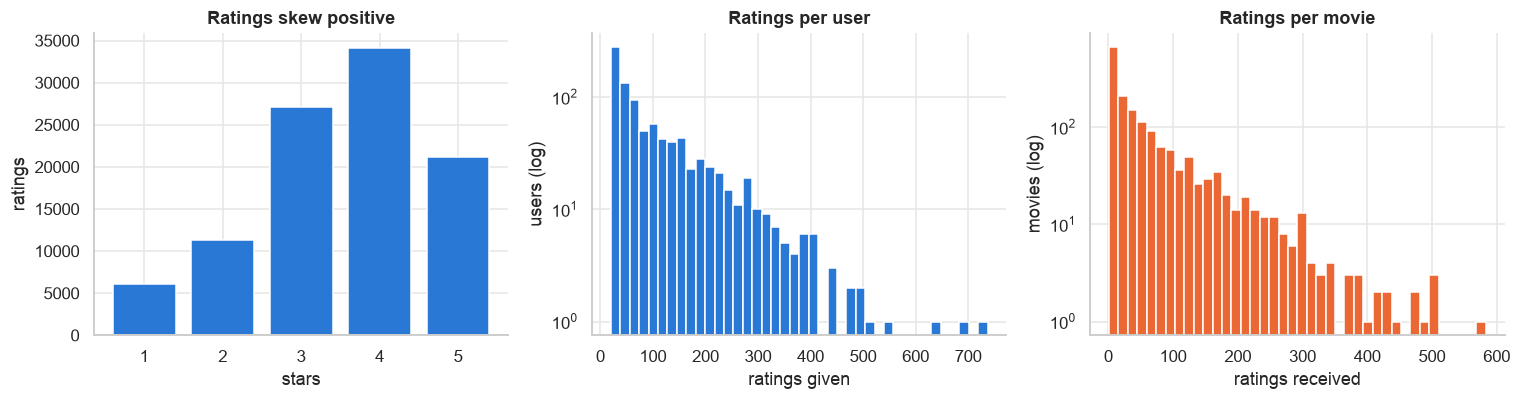

median user rated 65 movies (min 20, max 737); median movie got 27 ratings (min 1, max 583)


In [4]:
per_user = ratings.groupby("user").size(); per_item = ratings.groupby("item").size()
fig, ax = plt.subplots(1, 3, figsize=(14, 3.8))
vc = ratings["rating"].value_counts().sort_index()
ax[0].bar(vc.index, vc.values, color=BLUE); ax[0].set(title="Ratings skew positive", xlabel="stars", ylabel="ratings")
ax[1].hist(per_user, bins=40, color=BLUE); ax[1].set_yscale("log")
ax[1].set(title="Ratings per user", xlabel="ratings given", ylabel="users (log)")
ax[2].hist(per_item, bins=40, color=ORANGE); ax[2].set_yscale("log")
ax[2].set(title="Ratings per movie", xlabel="ratings received", ylabel="movies (log)")
plt.tight_layout(); plt.show()
print(f"median user rated {per_user.median():.0f} movies (min {per_user.min()}, max {per_user.max()}); median movie got {per_item.median():.0f} ratings (min {per_item.min()}, max {per_item.max()})")

### 2.2 Sparsity and the popularity long tail

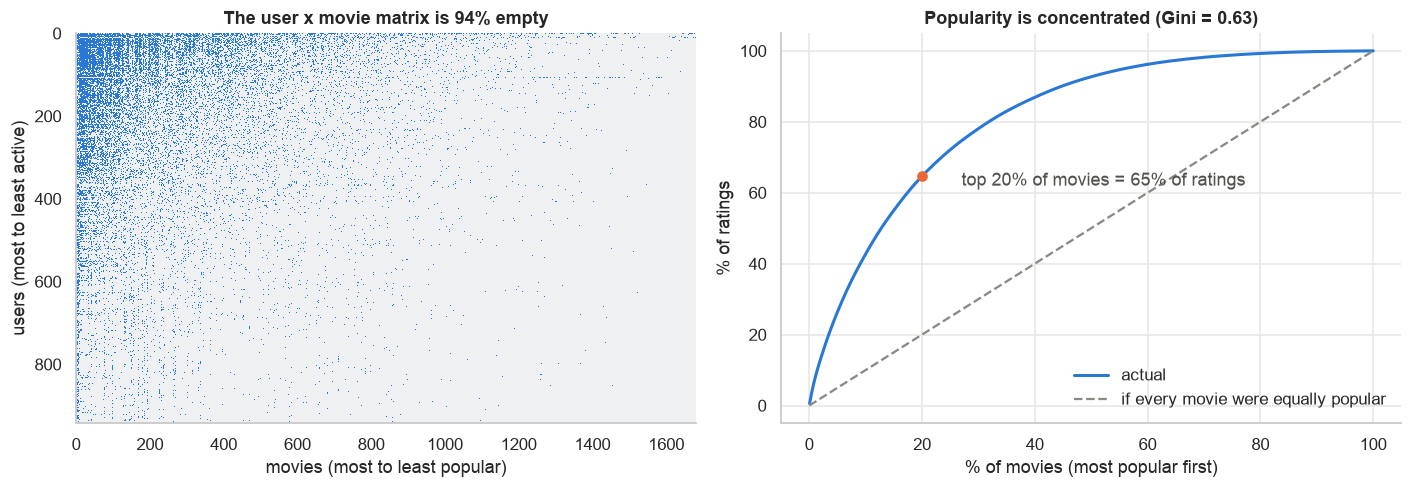

In [5]:
order_u = per_user.sort_values(ascending=False).index; order_i = per_item.sort_values(ascending=False).index
M = np.zeros((U, I), dtype=np.uint8); M[ratings["user"], ratings["item"]] = 1
Ms = M[np.ix_(order_u, order_i)]

pop_sorted = np.sort(per_item.values)[::-1]; cum = np.cumsum(pop_sorted)/pop_sorted.sum()
lorenz_x = np.arange(1, I+1)/I
asc = np.sort(per_item.values); gini = 1 - 2*np.trapezoid(np.cumsum(asc)/asc.sum(), dx=1/I)

fig, ax = plt.subplots(1, 2, figsize=(13, 4.6))
ax[0].imshow(Ms, aspect="auto", cmap=SEQ, interpolation="nearest", vmin=0, vmax=1)
ax[0].set(title=f"The user x movie matrix is {1-M.mean():.0%} empty", xlabel="movies (most to least popular)", ylabel="users (most to least active)")
ax[0].grid(False)
ax[1].plot(lorenz_x*100, cum*100, color=BLUE, lw=2, label="actual")
ax[1].plot([0, 100], [0, 100], color=GRAY, ls="--", label="if every movie were equally popular")
k20 = int(.2*I); ax[1].plot(20, cum[k20-1]*100, "o", color=ORANGE); ax[1].annotate(f"top 20% of movies = {cum[k20-1]:.0%} of ratings", (20, cum[k20-1]*100), (27, 62), color="#52514e")
ax[1].set(title=f"Popularity is concentrated (Gini = {gini:.2f})", xlabel="% of movies (most popular first)", ylabel="% of ratings"); ax[1].legend(frameon=False, loc="lower right")
plt.tight_layout(); plt.show()

**Why this matters.** The matrix is almost empty, so most user-movie pairs have no data, which is exactly why we need models that *generalise* instead of memorising. And because a few blockbusters hold most of the ratings, a model that only suggests blockbusters will look decent. We keep that in mind when we evaluate.

### 2.3 Genres and time

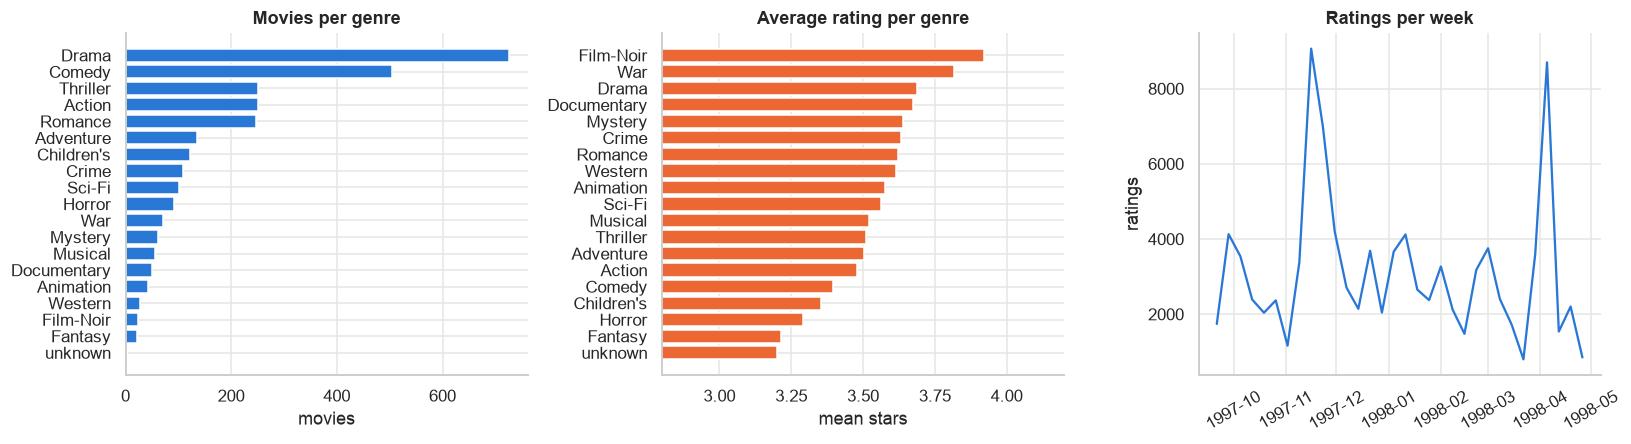

In [6]:
gcount = pd.Series(G.sum(0), index=genre_names)
rg = ratings.merge(movies[genre_names].reset_index(), on="item")
avg_by_genre = pd.Series({g: rg.loc[rg[g] == 1, "rating"].mean() for g in genre_names})
daily = ratings.set_index("when").resample("W")["rating"].count()
fig, ax = plt.subplots(1, 3, figsize=(15, 4.2))
s = gcount.sort_values(); ax[0].barh(s.index, s.values, color=BLUE); ax[0].set(title="Movies per genre", xlabel="movies")
a = avg_by_genre.sort_values(); ax[1].barh(a.index, a.values, color=ORANGE); ax[1].set_xlim(2.8, 4.2); ax[1].set(title="Average rating per genre", xlabel="mean stars")
ax[2].plot(daily.index, daily.values, color=BLUE); ax[2].set(title="Ratings per week", ylabel="ratings"); ax[2].tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.show()

Genres overlap (one movie can be Action *and* Thriller), and ratings arrive in bursts over about seven months. The time dimension is what lets us test a *sequence* model later: we know what each user rated first and what they rated last.

## 3. Evaluating a recommender properly

Evaluation is where many recommender results go wrong (see Dacrema et al., 2019, and Krichene & Rendle, 2020). We follow a strict protocol:

- **Time-based leave-one-out.** For each user, their **last** interaction is the **test** item and the one before it is **validation**. Everything earlier is training. This mimics reality: predict what a user does *next*, never using the future.
- **Implicit feedback.** Any rating counts as "the user chose to watch this". (Rating a movie 1 star still tells us what they watched.)
- **Full ranking.** We rank *all* items the user has not seen, not a handful of sampled negatives. Sampled metrics can reorder models.
- **Metrics.** **HR@10** (hit rate: is the held-out movie in the top 10?) and **NDCG@10** (same, but a hit at rank 1 counts more than at rank 10).
- **Honest uncertainty.** With 943 test users, each metric has noise of about +/-2 points. We report **bootstrap 95% confidence intervals**, and treat gaps smaller than that as ties.
- **Tuning on validation only.** Hyper-parameters are chosen on the validation item; the final models are refit on train+validation and scored once on test.

In [7]:
df = ratings.sort_values(["user", "ts", "item"]).copy()
df["rk"] = df.groupby("user").cumcount(ascending=False)
test_df, val_df, train_df = df[df.rk == 0], df[df.rk == 1], df[df.rk >= 2]
trval_df = df[df.rk >= 1]

def to_matrix(d):
    M = np.zeros((U, I), np.float32); M[d["user"], d["item"]] = 1; return M
R_tr, R_trval = to_matrix(train_df), to_matrix(trval_df)
y_val = val_df.sort_values("user")["item"].values
y_test = test_df.sort_values("user")["item"].values
print(f"train {len(train_df):,} | validation {len(val_df)} | test {len(test_df)}")

_jit = np.random.default_rng(SEED).random((U, I)).astype(np.float32) * 1e-6    # random tie-breaking

def ranks_of(scores, seen, target):
    # 1-based rank of the held-out item among all items the user has not already seen
    s = scores.astype(np.float32) + _jit
    s = np.where(seen > 0, -np.inf, s)
    t = s[np.arange(U), target]
    return (s > t[:, None]).sum(1) + 1

def metrics(rk, k=10):
    return {"HR@10": (rk <= k).mean(), "NDCG@10": np.where(rk <= k, 1/np.log2(rk+1), 0).mean()}

def boot_ci(per_user_vals, n=1000, seed=1):
    r = np.random.default_rng(seed); idx = r.integers(0, len(per_user_vals), (n, len(per_user_vals)))
    m = per_user_vals[idx].mean(1); return np.percentile(m, [2.5, 97.5])

train 98,114 | validation 943 | test 943


## 4. Seven recommenders, from simple to modern

Each model produces one score for every (user, item) pair. We build them in order of sophistication.

### 4.1 Baseline: popularity
Recommend the most-rated movies the user hasn't seen. Embarrassingly simple, and (as in notebook 01) surprisingly hard to beat. Every model must clear this bar.

In [8]:
def fit_popularity(R, **_):
    return np.tile(R.sum(0), (R.shape[0], 1))

### 4.2 Association rules (the notebook-01 idea)
For each pair of movies A, B count how often the same user has both. Score a candidate B by the **best confidence** `P(B | A)` over movies A the user has already seen. Pairs seen by fewer than 5 users are ignored (a minimum-support threshold).

In [9]:
def fit_rules(R, min_pair=5, **_):
    co = R.T @ R; np.fill_diagonal(co, 0)
    cnt = R.sum(0)
    conf = np.where(co >= min_pair, co / (cnt[:, None] + 1e-9), 0)     # conf[a, b] = P(b | a)
    out = np.zeros((R.shape[0], R.shape[1]), np.float32)
    for u in range(R.shape[0]):                                          # best rule that fires for this user
        out[u] = conf[R[u] > 0].max(0) if R[u].any() else 0
    return out

### 4.3 Item-based collaborative filtering (Sarwar et al., 2001)
Instead of rules, use **cosine similarity** between movies' user vectors. Two movies are similar if the same people watched them. A candidate's score is the sum of its similarity to what the user has watched. This is the "people who watched X also watched Y" engine behind early Amazon.

In [10]:
def fit_itemknn(R, shrink=10, **_):
    co = R.T @ R; n = np.sqrt(R.sum(0)) + 1e-9
    S = co / np.outer(n, n) * (co / (co + shrink))                       # cosine, shrunk for rarely co-watched pairs
    np.fill_diagonal(S, 0)
    return R @ S

### 4.4 Matrix factorisation by SVD (Koren et al., 2009)
Compress the huge sparse matrix into a small number of **latent factors** (say 32). Each user and each movie becomes a 32-number vector, and the score is their dot product. This is where *generalisation* comes from: a user who watched `Toy Story` can be matched to `A Bug's Life` through shared factors even if no one has linked them directly.

In [11]:
def fit_svd(R, k=32, **_):
    svd = TruncatedSVD(k, random_state=SEED); Z = svd.fit_transform(R)
    return Z @ svd.components_

### 4.5 Implicit ALS (Hu, Koren & Volinsky, 2008)
Also matrix factorisation, but trained with a loss that is aware that *no interaction* does not mean *dislike*. Observed entries get a higher confidence weight, and **Alternating Least Squares** solves for users and items in turn (each step is a closed-form linear solve). This was the workhorse of production recommenders for years.

In [12]:
def fit_als(R, k=32, alpha=2.0, reg=10.0, iters=10, seed=SEED, hook=None, **_):
    rng = np.random.default_rng(seed); n_u, n_i = R.shape
    X = rng.normal(0, .1, (n_u, k)); Y = rng.normal(0, .1, (n_i, k))
    by_user = [np.flatnonzero(R[u]) for u in range(n_u)]; by_item = [np.flatnonzero(R[:, i]) for i in range(n_i)]
    for it in range(iters):
        for A, B, idx in ((X, Y, by_user), (Y, X, by_item)):
            BtB = B.T @ B + reg * np.eye(k)
            for n in range(len(A)):
                Bi = B[idx[n]]
                A[n] = np.linalg.solve(BtB + alpha * Bi.T @ Bi, (1 + alpha) * Bi.sum(0))
        if hook: hook(it, X @ Y.T)
    fit_als.factors = (X, Y)
    return X @ Y.T

### 4.6 BPR: learning to rank directly (Rendle et al., 2009)
Instead of reconstructing the matrix, optimise what we care about: **a movie the user watched should score higher than one they did not**. Training samples triples *(user, watched movie, random unwatched movie)* and pushes the pair apart with stochastic gradient descent on `-log sigmoid(score_pos - score_neg)`. The model is still user-vector times item-vector, only the **loss** changes. Ranking losses of this kind (and their sampled-softmax cousins) are what neural two-tower retrievers are trained with.

In [13]:
def fit_bpr(R, k=32, lr=0.02, reg=0.01, epochs=80, batch=256, seed=SEED, hook=None, **_):
    rng = np.random.default_rng(seed); n_u, n_i = R.shape
    P = rng.normal(0, .1, (n_u, k)); Q = rng.normal(0, .1, (n_i, k)); b = np.zeros(n_i)
    uu, ii = np.nonzero(R); losses = []
    for ep in range(epochs):
        perm = rng.permutation(len(uu)); tot = 0.0
        for s in range(0, len(perm), batch):
            p = perm[s:s+batch]; u, i = uu[p], ii[p]; j = rng.integers(0, n_i, len(p))
            pu, qi, qj = P[u], Q[i], Q[j]
            x = b[i] - b[j] + (pu * (qi - qj)).sum(1); g = 1 / (1 + np.exp(x)); tot += np.log1p(np.exp(-x)).sum()
            np.add.at(P, u, lr * (g[:, None] * (qi - qj) - reg * pu))
            np.add.at(Q, i, lr * (g[:, None] * pu - reg * qi)); np.add.at(Q, j, lr * (-g[:, None] * pu - reg * qj))
            np.add.at(b, i, lr * (g - reg * b[i])); np.add.at(b, j, lr * (-g - reg * b[j]))
        losses.append(tot / len(uu))
        if hook: hook(ep, P @ Q.T + b)
    fit_bpr.factors = (P, Q); fit_bpr.losses = losses
    return P @ Q.T + b

### 4.7 A sequence-aware model
So far, order did not matter. But what you watch **next** depends strongly on what you watched **just now**. Sequential recommenders (GRU4Rec, SASRec, BERT4Rec, and today's generative models, see section 9) model exactly this. The simplest version is a **Markov chain**: count how often movie B follows movie A (and, with lower weight, B following A after one or two other movies), then score candidates from the user's most recent movie. Blended with a little popularity to break ties, it is a small stand-in for those far larger models.

In [14]:
def fit_markov(R_unused=None, seq_df=None, lam=1.0, windows=(1, 2, 3), **_):
    T = np.zeros((I, I), np.float32)
    for _, g in seq_df.groupby("user"):
        it = g.sort_values(["ts", "item"])["item"].values
        for w in windows:
            if len(it) > w: np.add.at(T, (it[:-w], it[w:]), 1.0 / w)
    Tn = T / (T.sum(1, keepdims=True) + 1e-9)
    last = seq_df.sort_values(["user", "ts", "item"]).groupby("user")["item"].last().reindex(range(U)).values
    pop = seq_df.groupby("item").size().reindex(range(I), fill_value=0).values.astype(np.float32)
    return Tn[last] + lam * pop / pop.sum()

### 4.8 Tuning on the validation item
A small, honest search. We look at **latent dimension** for the factor models and watch how ALS and BPR improve **per iteration** (these curves also appear later).

tuning took 47s


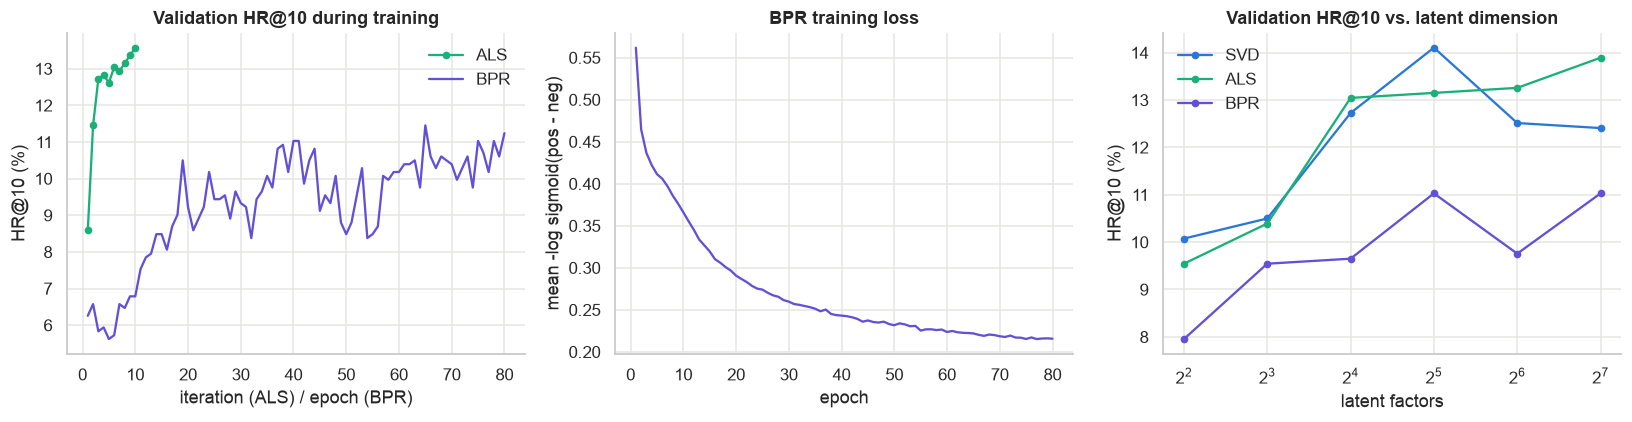

In [15]:
curves = {"ALS": [], "BPR": []}
als_hook = lambda it, S: curves["ALS"].append(metrics(ranks_of(S, R_tr, y_val))["HR@10"])
bpr_hook = lambda ep, S: curves["BPR"].append(metrics(ranks_of(S, R_tr, y_val))["HR@10"])
t0 = time.time()
fit_als(R_tr, hook=als_hook); fit_bpr(R_tr, hook=bpr_hook)
bpr_losses = list(fit_bpr.losses)

dims = [4, 8, 16, 32, 64, 128]; sweep = {"SVD": [], "ALS": [], "BPR": []}
for k in dims:
    sweep["SVD"].append(metrics(ranks_of(fit_svd(R_tr, k=k), R_tr, y_val))["HR@10"])
    sweep["ALS"].append(metrics(ranks_of(fit_als(R_tr, k=k, iters=8), R_tr, y_val))["HR@10"])
    sweep["BPR"].append(metrics(ranks_of(fit_bpr(R_tr, k=k, epochs=40), R_tr, y_val))["HR@10"])
print(f"tuning took {time.time()-t0:.0f}s")

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for name, col in (("ALS", AQUA), ("BPR", VIOLET)):
    ax[0].plot(np.arange(1, len(curves[name])+1), np.array(curves[name])*100, "o-" if name == "ALS" else "-", color=col, label=name, ms=4)
ax[0].set(title="Validation HR@10 during training", xlabel="iteration (ALS) / epoch (BPR)", ylabel="HR@10 (%)"); ax[0].legend(frameon=False)
ax[1].plot(np.arange(1, len(bpr_losses)+1), bpr_losses, color=VIOLET); ax[1].set(title="BPR training loss", xlabel="epoch", ylabel="mean -log sigmoid(pos - neg)")
for name, col in (("SVD", BLUE), ("ALS", AQUA), ("BPR", VIOLET)):
    ax[2].plot(dims, np.array(sweep[name])*100, "o-", color=col, label=name, ms=4)
ax[2].set_xscale("log", base=2); ax[2].set(title="Validation HR@10 vs. latent dimension", xlabel="latent factors", ylabel="HR@10 (%)"); ax[2].legend(frameon=False)
plt.tight_layout(); plt.show()

**How to read this.**
- **ALS** converges fast: most of the gain arrives in the first 2-3 iterations.
- **BPR** is slower and noisier: its training loss falls smoothly, while validation accuracy climbs for roughly 40 epochs and then plateaus around 10-11%, with +/-1 point of jitter from one epoch to the next (only 943 validation users). We train it for 80 epochs below.
- **Latent dimension:** SVD improves up to about 32 factors and then declines, which is the classic over-fitting pattern: too few factors under-fit, too many memorise. ALS and BPR are flatter. With 943 validation users the curves are noisy, so use them for their *shape*, not to pick a winner by decimals. We use 32 factors.

## 5. Results on the test set

Final models are refit on train + validation and scored once on the held-out last movie of each user.

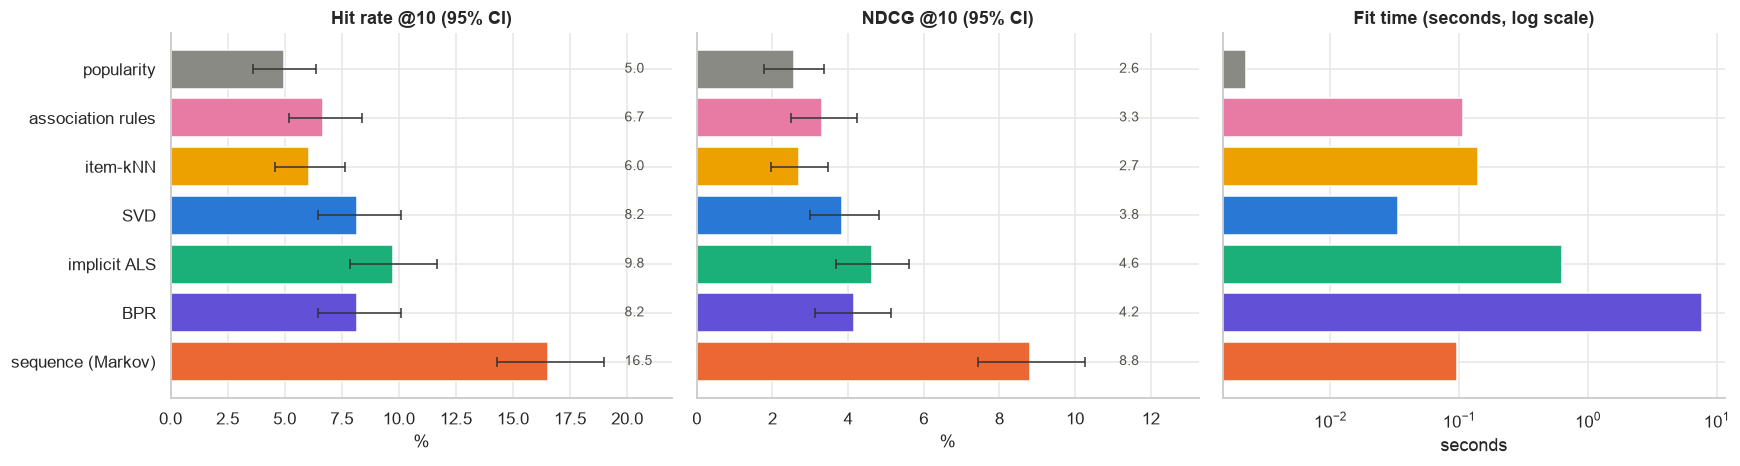

,HR@10,HR lo,HR hi,NDCG@10,train s
model,,,,,
popularity,0.050,0.036,0.064,0.026,0.002
association rules,0.067,0.052,0.084,0.033,0.107
item-kNN,0.060,0.046,0.076,0.027,0.139
SVD,0.082,0.065,0.101,0.038,0.034
implicit ALS,0.098,0.078,0.117,0.046,0.623
BPR,0.082,0.065,0.101,0.042,7.689
sequence (Markov),0.165,0.143,0.190,0.088,0.096


In [16]:
HP = dict(k=32)
models = {
    "popularity":         lambda: fit_popularity(R_trval),
    "association rules":  lambda: fit_rules(R_trval),
    "item-kNN":           lambda: fit_itemknn(R_trval),
    "SVD":                lambda: fit_svd(R_trval, **HP),
    "implicit ALS":       lambda: fit_als(R_trval, **HP),
    "BPR":                lambda: fit_bpr(R_trval, **HP),
    "sequence (Markov)":  lambda: fit_markov(seq_df=trval_df),
}
SC, RK, secs = {}, {}, {}
for name, f in models.items():
    t0 = time.time(); SC[name] = f(); secs[name] = time.time() - t0
    RK[name] = ranks_of(SC[name], R_trval, y_test)

rows = []
for name in models:
    hit = (RK[name] <= 10).astype(float); nd = np.where(RK[name] <= 10, 1/np.log2(RK[name]+1), 0)
    lo, hi = boot_ci(hit); nlo, nhi = boot_ci(nd)
    rows.append({"model": name, "HR@10": hit.mean(), "HR lo": lo, "HR hi": hi, "NDCG@10": nd.mean(), "NDCG lo": nlo, "NDCG hi": nhi, "train s": secs[name]})
res = pd.DataFrame(rows).set_index("model")

fig, ax = plt.subplots(1, 3, figsize=(16, 4.4))
cols = [GRAY, MAGENTA, YELLOW, BLUE, AQUA, VIOLET, ORANGE]
for a, m, lo, hi, t in ((ax[0], "HR@10", "HR lo", "HR hi", "Hit rate @10 (95% CI)"), (ax[1], "NDCG@10", "NDCG lo", "NDCG hi", "NDCG @10 (95% CI)")):
    y = np.arange(len(res))[::-1]
    a.barh(y, res[m]*100, color=cols, xerr=[(res[m]-res[lo])*100, (res[hi]-res[m])*100], error_kw=dict(ecolor="#333", lw=1, capsize=3))
    a.set_yticks(y, res.index); a.set(title=t, xlabel="%")
    for yi, v in zip(y, res[m]*100): a.text(res[hi].max()*100 + 0.9, yi, f"{v:.1f}", va="center", fontsize=9, color="#52514e")
    a.set_xlim(0, res[hi].max()*100 + 3)
ax[1].set_yticklabels([])
y = np.arange(len(res))[::-1]; ax[2].barh(y, res["train s"], color=cols); ax[2].set_xscale("log"); ax[2].set_yticks(y, res.index); ax[2].set_yticklabels([])
ax[2].set(title="Fit time (seconds, log scale)", xlabel="seconds")
plt.tight_layout(); plt.show()
res[["HR@10", "HR lo", "HR hi", "NDCG@10", "train s"]].round(3)

In [17]:
best = res["HR@10"].idxmax(); pop_hr = res.loc["popularity", "HR@10"]
non_seq = res.drop(index="sequence (Markov)")["HR@10"]
print(f"Popularity baseline: {pop_hr:.1%}.  Best non-sequential model: {non_seq.idxmax()} at {non_seq.max():.1%}.  Best overall: {best} at {res.loc[best,'HR@10']:.1%}.")
print(f"Sequence model vs best non-sequential: +{(res.loc['sequence (Markov)','HR@10']-non_seq.max())*100:.1f} points "
      f"(CI of sequence model {res.loc['sequence (Markov)','HR lo']:.1%}-{res.loc['sequence (Markov)','HR hi']:.1%}; best non-seq CI {res.loc[non_seq.idxmax(),'HR lo']:.1%}-{res.loc[non_seq.idxmax(),'HR hi']:.1%}).")

Popularity baseline: 5.0%.  Best non-sequential model: implicit ALS at 9.8%.  Best overall: sequence (Markov) at 16.5%.
Sequence model vs best non-sequential: +6.8 points (CI of sequence model 14.3%-19.0%; best non-seq CI 7.8%-11.7%).


**Reading the results.**
- Learned models land above the popularity baseline, but the gaps are modest. For association rules and item-kNN the confidence intervals still overlap the baseline, so we cannot call those two clear wins on 943 users.
- **SVD, ALS and BPR are within a point or two of each other** and their intervals overlap heavily. Do not read their order as a ranking: it would likely change with another seed or split.
- **Order is the big effect.** The Markov chain uses *no* user embedding at all, yet its interval does not overlap any other model's. "What comes next" depends on "what just happened", which is exactly the signal sequence models exploit.
- Costs differ a lot (right panel, log scale): popularity, SVD and the Markov chain are nearly free, ALS takes under a second, and BPR (many small SGD steps in plain numpy) takes the longest.

### 5.1 How deep into the list do we need to look?

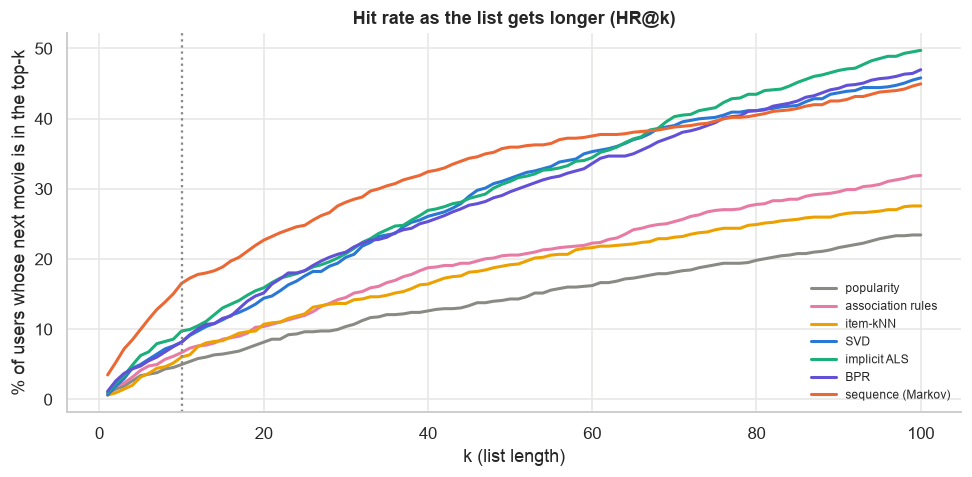

In [18]:
ks = np.arange(1, 101)
fig, ax = plt.subplots(figsize=(9, 4.5))
for (name, rk), c in zip(RK.items(), cols):
    ax.plot(ks, [(rk <= k).mean()*100 for k in ks], color=c, lw=2, label=name)
ax.set(title="Hit rate as the list gets longer (HR@k)", xlabel="k (list length)", ylabel="% of users whose next movie is in the top-k")
ax.axvline(10, color=GRAY, ls=":"); ax.legend(frameon=False, fontsize=8, loc="lower right")
plt.tight_layout(); plt.show()

## 6. What did the model actually learn?

A factor model gives every movie a 32-number **embedding**. If those numbers are meaningful, movies that are alike should be close together, even though we never told the model about genres or plots. We take the **BPR** embeddings, squash them to 2D with t-SNE, and colour by genre.

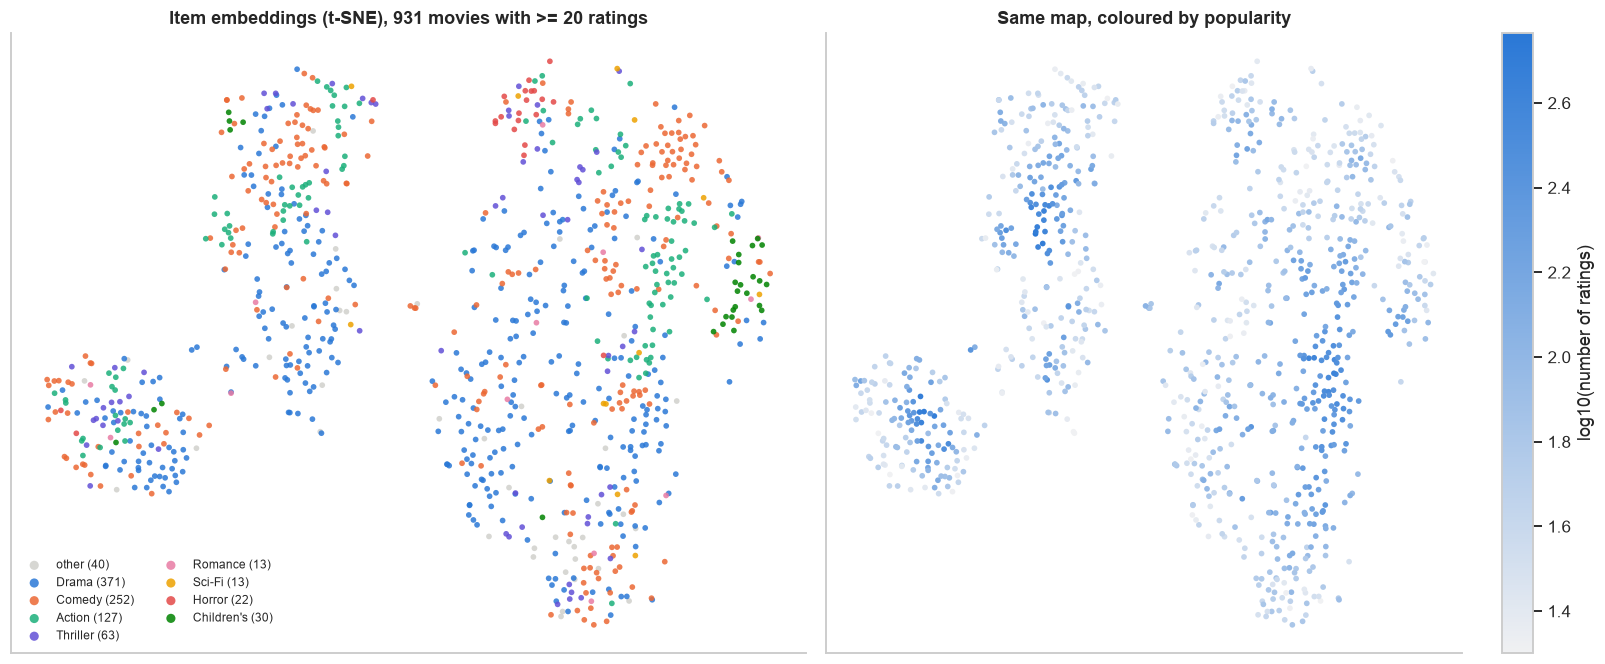

In [19]:
Pq = fit_bpr.factors[1]   # BPR item factors (last fit: train+validation)
Qn = Pq / (np.linalg.norm(Pq, axis=1, keepdims=True) + 1e-9)
n_ratings = R_trval.sum(0)
keep = n_ratings >= 20                                        # movies with enough data to have a stable embedding
Z = TSNE(2, perplexity=30, init="pca", random_state=SEED, learning_rate="auto").fit_transform(Qn[keep])
main = ["Drama", "Comedy", "Action", "Thriller", "Romance", "Sci-Fi", "Horror", "Children's"]
gi = {g: genre_names.index(g) for g in main}
kept_ids = np.flatnonzero(keep)
lab = np.array(["other"] * len(kept_ids), dtype=object)
for g in main[::-1]:
    lab[G[kept_ids, gi[g]] > 0] = g
pal = dict(zip(main, [BLUE, ORANGE, AQUA, VIOLET, MAGENTA, YELLOW, "#e34948", "#008300"])); pal["other"] = "#d0d0cc"

fig, ax = plt.subplots(1, 2, figsize=(15, 6.2))
for g in ["other"] + main:
    m = lab == g; ax[0].scatter(Z[m, 0], Z[m, 1], s=14, c=pal[g], label=f"{g} ({m.sum()})", alpha=.85, edgecolor="none")
ax[0].legend(frameon=False, fontsize=8, markerscale=1.6, ncol=2); ax[0].set(title=f"Item embeddings (t-SNE), {keep.sum()} movies with >= 20 ratings"); ax[0].set_xticks([]); ax[0].set_yticks([])
sc = ax[1].scatter(Z[:, 0], Z[:, 1], s=14, c=np.log10(n_ratings[kept_ids]), cmap=SEQ, edgecolor="none")
plt.colorbar(sc, ax=ax[1], label="log10(number of ratings)"); ax[1].set(title="Same map, coloured by popularity"); ax[1].set_xticks([]); ax[1].set_yticks([])
plt.tight_layout(); plt.show()

**How to read it.** Colour shows the genre, which we never gave to the model. Some genres do form visible pockets (Action, Horror and Children's each gather in their own regions), so the model picked up part of the genre structure *from behaviour alone*. Drama and Comedy, the two biggest genres, are spread across the whole map: taste cuts across genres, as it does for real people. The second map shows that **popularity is encoded in the geometry too** (heavily rated movies sit in particular regions), which feeds the popularity bias we measure in section 7.

In [20]:
def neighbours(title_part, n=6):
    i = int(np.flatnonzero(pd.Series(titles).str.contains(title_part, regex=False).values)[0])
    sim = Qn @ Qn[i]; sim[i] = -1; sim[n_ratings < 20] = -1
    top = np.argsort(-sim)[:n]
    return titles[i], [(titles[j], round(float(sim[j]), 2)) for j in top]
for q in ["Toy Story (1995)", "Star Wars (1977)", "Pulp Fiction (1994)", "Fargo (1996)"]:
    t, nn = neighbours(q); print(f"{t}\n   -> " + "\n   -> ".join(f"{a}  ({b})" for a, b in nn) + "\n")

Toy Story (1995)
   -> Return of the Jedi (1983)  (0.9)
   -> Star Wars (1977)  (0.85)
   -> Willy Wonka and the Chocolate Factory (1971)  (0.84)
   -> Independence Day (ID4) (1996)  (0.83)
   -> Fargo (1996)  (0.82)
   -> Twelve Monkeys (1995)  (0.81)

Star Wars (1977)
   -> Return of the Jedi (1983)  (0.91)
   -> Independence Day (ID4) (1996)  (0.87)
   -> Toy Story (1995)  (0.85)
   -> Rock, The (1996)  (0.8)
   -> Fargo (1996)  (0.8)
   -> Star Trek: First Contact (1996)  (0.79)

Pulp Fiction (1994)
   -> Silence of the Lambs, The (1991)  (0.86)
   -> Fugitive, The (1993)  (0.83)
   -> Alien (1979)  (0.8)
   -> Usual Suspects, The (1995)  (0.79)
   -> Raiders of the Lost Ark (1981)  (0.78)
   -> GoodFellas (1990)  (0.77)

Fargo (1996)
   -> Twelve Monkeys (1995)  (0.84)
   -> Toy Story (1995)  (0.82)
   -> Godfather, The (1972)  (0.81)
   -> Star Wars (1977)  (0.8)
   -> Leaving Las Vegas (1995)  (0.79)
   -> People vs. Larry Flynt, The (1996)  (0.77)



Nearest neighbours are the **item-to-item recommendations** you would show on a "more like this" shelf. Sensible neighbours here come purely from who watched what.

## 7. Beyond accuracy

A model can top an accuracy table and still be a poor product. Three things to check.

### 7.1 Popularity bias and diversity
What does each model *actually put on screen*? We compute, over everyone's top-10: the **coverage** (share of the catalogue ever recommended), the **average popularity percentile** of recommended items, and the **intra-list diversity** (average genre dissimilarity inside a list).

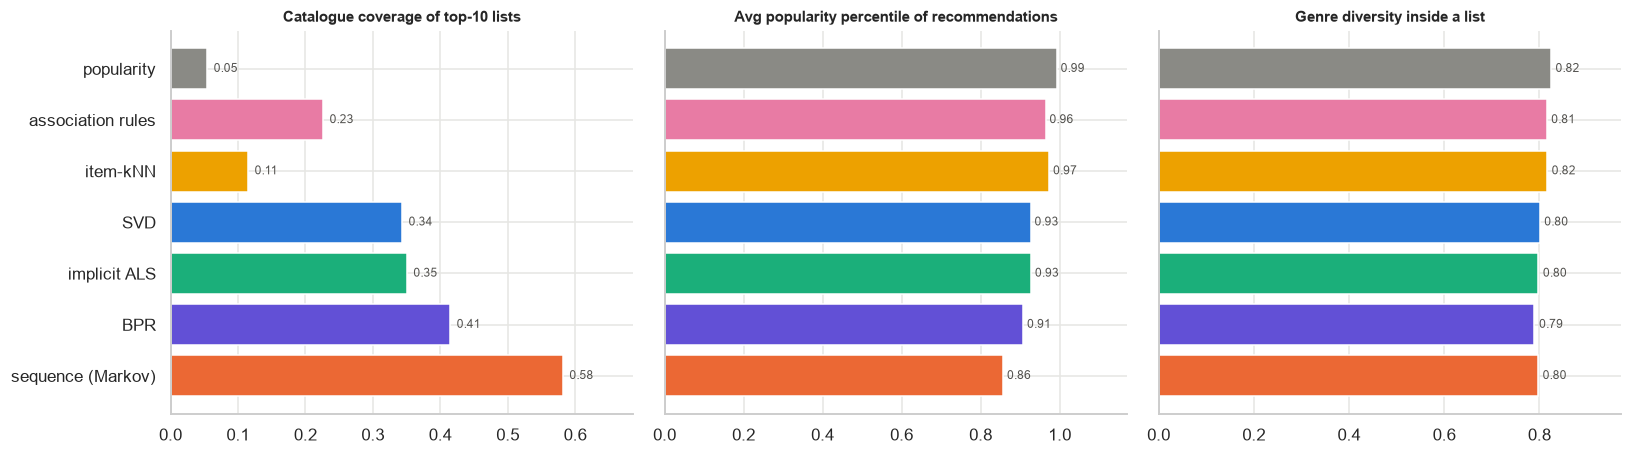

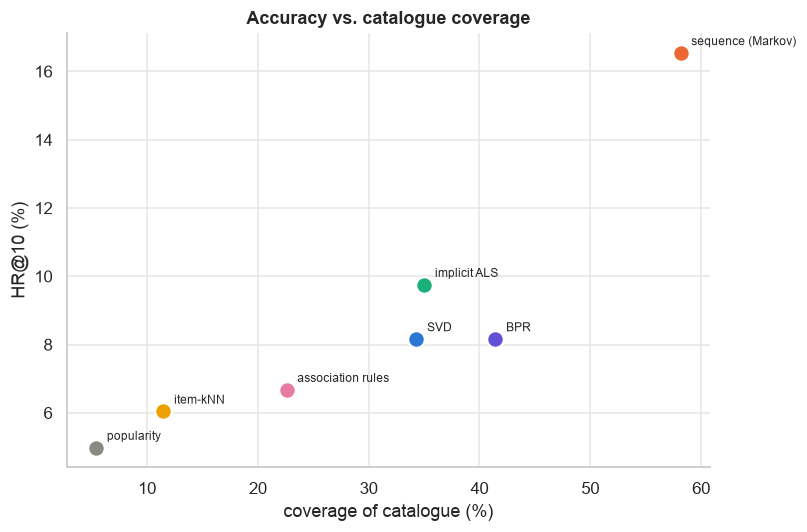

In [21]:
pop_pct = pd.Series(n_ratings).rank(pct=True).values       # 1.0 = most popular movie
def top_lists(S, seen, k=10):
    s = np.where(seen > 0, -np.inf, S.astype(np.float32) + _jit); return np.argsort(-s, axis=1)[:, :k]
def diversity(top):
    d = []
    for row in top:
        g = G[row]; inter = g @ g.T; un = g.sum(1)[:, None] + g.sum(1)[None, :] - inter
        jac = np.where(un > 0, inter / np.maximum(un, 1), 1); n = len(row); d.append(1 - (jac.sum() - n) / (n * (n - 1)))
    return float(np.mean(d))
TOP = {n: top_lists(SC[n], R_trval) for n in models}
bb = pd.DataFrame({
    "coverage": {n: len(np.unique(t)) / I for n, t in TOP.items()},
    "avg popularity percentile": {n: pop_pct[t].mean() for n, t in TOP.items()},
    "genre diversity": {n: diversity(t) for n, t in TOP.items()},
    "HR@10": res["HR@10"]})
fig, ax = plt.subplots(1, 3, figsize=(15, 4.3))
y = np.arange(len(bb))[::-1]
for a, c, t in ((ax[0], "coverage", "Catalogue coverage of top-10 lists"), (ax[1], "avg popularity percentile", "Avg popularity percentile of recommendations"), (ax[2], "genre diversity", "Genre diversity inside a list")):
    a.barh(y, bb[c], color=cols); a.set_yticks(y, bb.index if a is ax[0] else [""]*len(bb)); a.set_title(t, fontsize=10)
    for yi, v in zip(y, bb[c]): a.text(v + .01, yi, f"{v:.2f}", va="center", fontsize=8, color="#52514e")
    a.set_xlim(0, bb[c].max()*1.18)
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(7.5, 5))
for (n, r), c in zip(bb.iterrows(), cols):
    ax.scatter(r["coverage"]*100, r["HR@10"]*100, s=120, color=c, edgecolor="white", linewidth=1.5, zorder=3); ax.annotate(n, (r["coverage"]*100, r["HR@10"]*100), (7, 5), textcoords="offset points", fontsize=8)
ax.set(title="Accuracy vs. catalogue coverage", xlabel="coverage of catalogue (%)", ylabel="HR@10 (%)"); plt.tight_layout(); plt.show()

**Reading it.**
- A popularity list shows the same ~5% of the catalogue to everyone. Item-kNN is barely better (11%), and association rules reach 23%.
- The factor models cover roughly 35-40% of the catalogue and the sequence model about 58%. The sequence model is also the one whose recommendations are least dominated by blockbusters (average popularity percentile 0.86 vs. 0.91-0.99 for the others).
- Genre diversity inside a list is nearly identical for every model (0.80-0.82), so no model here buys diversity with its accuracy.
- Here the most accurate model (sequence) is also the one with the widest coverage, so there is no accuracy-vs-coverage trade-off *within this set*. Do not expect that to hold in general.

### 7.2 Who gets served well? User cold start and item cold start

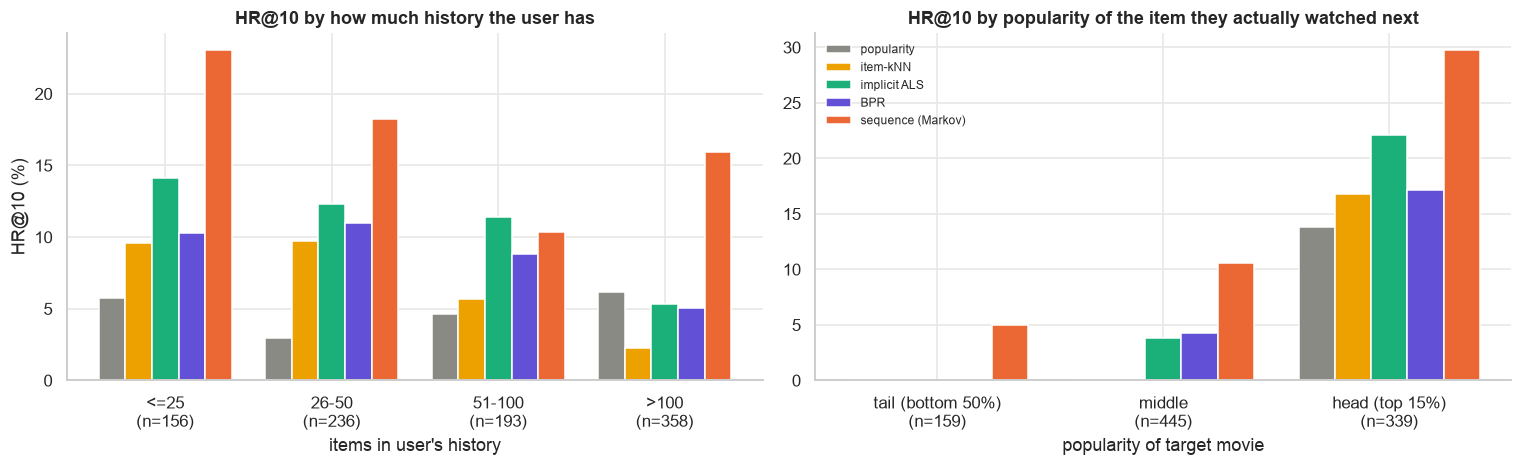

In [22]:
n_hist = R_trval.sum(1)
ub = pd.cut(n_hist, [0, 25, 50, 100, 1e9], labels=["<=25", "26-50", "51-100", ">100"])
ib = pd.cut(pop_pct[y_test], [0, .5, .85, 1.0], labels=["tail (bottom 50%)", "middle", "head (top 15%)"])
show = ["popularity", "item-kNN", "implicit ALS", "BPR", "sequence (Markov)"]; cmap = dict(zip(models, cols))
fig, ax = plt.subplots(1, 2, figsize=(14, 4.4))
w = .16
for j, n in enumerate(show):
    h = (RK[n] <= 10)
    a = pd.Series(h).groupby(ub).mean(); b2 = pd.Series(h).groupby(ib).mean()
    ax[0].bar(np.arange(len(a)) + (j-2)*w, a.values*100, w, color=cmap[n], label=n)
    ax[1].bar(np.arange(len(b2)) + (j-2)*w, b2.values*100, w, color=cmap[n], label=n)
ax[0].set_xticks(range(4), [f"{l}\n(n={c})" for l, c in ub.value_counts().sort_index().items()]); ax[0].set(title="HR@10 by how much history the user has", xlabel="items in user's history", ylabel="HR@10 (%)")
ax[1].set_xticks(range(3), [f"{l}\n(n={c})" for l, c in ib.value_counts().sort_index().items()]); ax[1].set(title="HR@10 by popularity of the item they actually watched next", xlabel="popularity of target movie"); ax[1].legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()

**Two classic problems in one picture** (bars come from 156-358 users each, so expect several points of noise).
- *Left, by user history:* the picture is not "more history = better". Heavy users (>100 items) have already seen most popular movies, so their next movie is harder to guess, and the factor models do worst there. The sequence model holds up best across all four groups. A genuinely *new* user (zero history) is not in this dataset, since MovieLens keeps only users with at least 20 ratings, and would get nothing from any of these models.
- *Right, by how popular the next movie is:* every model predicts blockbusters far better than niche movies. For the bottom half of the catalogue the hit rate is essentially **zero** for all models except the sequence model (about 5%). This is the **item cold-start / long-tail problem**. It is why modern systems add **content features** (genre, text, images) and why generative approaches (section 9) give each item a *semantic ID* built from its content.

## 8. One user, three models

Numbers hide what the user would actually see. Here is one user's most recent movies and the top 5 from three different models.

In [23]:
u = int(np.argsort(-n_hist)[len(n_hist)//4])    # a fairly active user (75th percentile of history size)
hist = trval_df[trval_df.user == u].sort_values("ts").tail(6)["item"].values
print(f"User {u}: {int(n_hist[u])} movies in history. Most recent:")
for i in hist: print("   *", titles[i], "|", ", ".join(g for g, f in zip(genre_names, G[i]) if f))
print("   held-out next movie:", titles[y_test[u]], "\n")
for n in ["popularity", "implicit ALS", "sequence (Markov)"]:
    print(f"{n}:")
    for i in TOP[n][u][:5]: print("   ->", titles[i], "|", ", ".join(g for g, f in zip(genre_names, G[i]) if f))

User 737: 147 movies in history. Most recent:
   * Godfather, The (1972) | Action, Crime, Drama
   * Winnie the Pooh and the Blustery Day (1968) | Animation, Children's
   * Hunt for Red October, The (1990) | Action, Thriller
   * Good, The Bad and The Ugly, The (1966) | Action, Western
   * Unforgiven (1992) | Western
   * M*A*S*H (1970) | Comedy, War
   held-out next movie: Mr. Smith Goes to Washington (1939) 

popularity:
   -> Liar Liar (1997) | Comedy
   -> English Patient, The (1996) | Drama, Romance, War
   -> Scream (1996) | Horror, Thriller
   -> Air Force One (1997) | Action, Thriller
   -> Jerry Maguire (1996) | Drama, Romance
implicit ALS:
   -> Sting, The (1973) | Comedy, Crime
   -> Butch Cassidy and the Sundance Kid (1969) | Action, Comedy, Western
   -> Beauty and the Beast (1991) | Animation, Children's, Musical
   -> Highlander (1986) | Action, Adventure
   -> Babe (1995) | Children's, Comedy, Drama
sequence (Markov):
   -> Butch Cassidy and the Sundance Kid (1969) | 

Popularity returns the same blockbusters for everyone. ALS reflects the user's overall taste profile. The sequence model is anchored to the last movie watched. One user is an anecdote, not evidence (the held-out movie was in none of the three lists), but it shows how different the lists are. Which is "better" depends on the product: a home page wants taste, a "watch next" button wants the sequence.

## 9. Where the field is now

What we built are the **building blocks**. Current systems extend them in four directions. We did not train these larger models here (they need GPUs and large datasets), but each one is a direct generalisation of something above.

| Idea | What changes vs. this notebook | Key paper |
|---|---|---|
| **Two-tower retrieval** | User and item embeddings come from neural networks over many features (not a lookup table); trained with sampled-softmax; served with approximate nearest-neighbour search | Covington et al. (2016); Yi et al. (2019) |
| **Sequential transformers** | The Markov chain is replaced by self-attention over the user's whole history | SASRec (Kang & McAuley, 2018); BERT4Rec (Sun et al., 2019) |
| **Generative retrieval** | Instead of scoring items, a model *generates the next item's ID*, token by token. Items get **semantic IDs** from their content, which helps cold-start items | TIGER (Rajput et al., 2023) |
| **Scaling laws, "generative recommenders"** | Recommendation reframed as sequence transduction; models with up to trillions of parameters; quality improves as a power law with compute | HSTU (Zhai et al., 2024) |

**Honest caveats the literature itself raises**
- Newer is not automatically better: many neural methods fail to beat tuned simple baselines (Dacrema et al., 2019), and a plain dot product beats the MLP "similarity" of Neural Collaborative Filtering once tuned (Rendle et al., 2020). One echo in our own results: a Markov chain of a few lines beat every factor model, and the three factor models were statistically tied with each other.
- Evaluation protocol decides the winner (full ranking vs. sampled negatives, time-based vs. random split).
- Offline accuracy is only a proxy: coverage, diversity, fairness and online A/B tests are what products are actually judged on.

## 10. Take-aways

1. **Association rules (notebook 01)** are transparent and cheap, but only use item co-occurrence, ignore *who* the user is, and ignore order.
2. **Learned embeddings** (SVD, ALS, BPR) let the model generalise across the sparse matrix and give a modest lift over popularity. They are close to each other, so the *choice of factorisation or loss* mattered less than people expect.
3. **Order is signal.** A tiny sequence model clearly outperformed every non-sequential model here, which is the intuition behind the field's move to transformers over user histories.
4. **Evaluate like a sceptic:** time-based split, full ranking, confidence intervals, and a popularity baseline.
5. **Accuracy is not the product.** Check popularity bias, coverage, diversity and cold start.

## References

**Data**
- Harper, F. M. & Konstan, J. A. (2015). *The MovieLens Datasets: History and Context.* ACM Transactions on Interactive Intelligent Systems 5(4), Article 19. DOI [10.1145/2827872](https://doi.org/10.1145/2827872). Data: [grouplens.org/datasets/movielens/100k](https://grouplens.org/datasets/movielens/100k/).

**Methods built in this notebook**
- Agrawal, R. & Srikant, R. (1994). *Fast algorithms for mining association rules.* VLDB. (Apriori, notebook 01.)
- Sarwar, B., Karypis, G., Konstan, J. & Riedl, J. (2001). *Item-based collaborative filtering recommendation algorithms.* WWW.
- Koren, Y., Bell, R. & Volinsky, C. (2009). *Matrix factorization techniques for recommender systems.* IEEE Computer 42(8).
- Hu, Y., Koren, Y. & Volinsky, C. (2008). *Collaborative filtering for implicit feedback datasets.* ICDM.
- Rendle, S., Freudenthaler, C., Gantner, Z. & Schmidt-Thieme, L. (2009). *BPR: Bayesian personalized ranking from implicit feedback.* UAI. [arXiv:1205.2618](https://arxiv.org/abs/1205.2618).

**Modern recommenders (section 9)**
- Covington, P., Adams, J. & Sargin, E. (2016). *Deep neural networks for YouTube recommendations.* RecSys.
- Yi, X. et al. (2019). *Sampling-bias-corrected neural modeling for large corpus item recommendations.* RecSys.
- Kang, W.-C. & McAuley, J. (2018). *Self-attentive sequential recommendation* (SASRec). ICDM. [arXiv:1808.09781](https://arxiv.org/abs/1808.09781).
- Sun, F. et al. (2019). *BERT4Rec: Sequential recommendation with bidirectional encoder representations from Transformer.* CIKM.
- Rajput, S. et al. (2023). *Recommender systems with generative retrieval* (TIGER). NeurIPS. [arXiv:2305.05065](https://arxiv.org/abs/2305.05065).
- Zhai, J. et al. (2024). *Actions speak louder than words: Trillion-parameter sequential transducers for generative recommendations* (HSTU). Meta AI. [arXiv:2402.17152](https://arxiv.org/abs/2402.17152).

**Evaluation and caution**
- Dacrema, M. F., Cremonesi, P. & Jannach, D. (2019). *Are we really making much progress? A worrying analysis of recent neural recommendation approaches.* RecSys. [arXiv:1907.06902](https://arxiv.org/abs/1907.06902).
- Rendle, S., Krichene, W., Zhang, L. & Anderson, J. (2020). *Neural collaborative filtering vs. matrix factorization revisited.* RecSys. [arXiv:2005.09683](https://arxiv.org/abs/2005.09683).
- Krichene, W. & Rendle, S. (2020). *On sampled metrics for item recommendation.* KDD.

*All models in this notebook are implemented from scratch with numpy/scikit-learn for learning purposes, and are not tuned production systems.*